# Phase 4 — Photo → text pipeline (segmentation + recognition + CER)

**Gate ("Done when")**: pipeline runs end-to-end on real photos; CER measured on
20-50 photos and documented; golden-test vectors exported for the Kotlin port;
failure gallery collected.

Order of work:
1. **Synthetic smoke test** — rendered text image, validates the pipeline before any photo exists
2. **Stage visualization** — see what binarization/segmentation actually does
3. **Real photos + CER** — `ml/test_images/*.jpg` each with a `<name>.gt.txt` ground truth
4. **Golden vectors** — frozen inputs/outputs that the Kotlin port must reproduce
5. **Failure gallery** — material for the report

In [3]:
import sys, pathlib, json
sys.path.append(str(pathlib.Path.cwd().parent))

import numpy as np
import cv2
import matplotlib.pyplot as plt

from src import preprocess as pp
from src.pipeline import Recognizer, transcribe, ARTIFACTS

TEST_IMAGES = pathlib.Path.cwd().parent / 'test_images'
rec = Recognizer()
print('recognizer ready (model_int8.tflite)')

recognizer ready (model_int8.tflite)


.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [4]:
import cv2
fname = 'print_sans_fox.jpg'
img = cv2.imread(str(TEST_IMAGES / fname))
print('loaded size:', img.shape[1], 'x', img.shape[0])
page = transcribe(img, rec)
gt = (TEST_IMAGES / fname.replace('.jpg', '.gt.txt')).read_text(encoding='utf-8')
print('GT :', ' '.join(gt.lower().split()))
print('HYP:', page.text)
print('lines:', len(page.lines), '| characters:', sum(len(l.chars) for l in page.lines))

loaded size: 3468 x 4624
GT : the quick brown fox jumps over the lazy dog
HYP: the quick brown fox
jumps over the lazy dog
lines: 2 | characters: 35


## 1. Synthetic smoke test
A rendered image of known text — zero photo logistics, instant feedback.
If the pipeline can't read THIS, no point photographing anything yet.

In [3]:
from PIL import Image, ImageDraw, ImageFont

def render_text(lines, size=36, pad=40):
    try:
        font = ImageFont.truetype('arial.ttf', size)
    except OSError:
        font = ImageFont.load_default(size)
    w = max(int(font.getlength(l)) for l in lines) + 2*pad
    h = len(lines) * int(size*1.8) + 2*pad
    img = Image.new('L', (w, h), 235)            # light paper
    d = ImageDraw.Draw(img)
    for i, l in enumerate(lines):
        d.text((pad, pad + i*int(size*1.8)), l, fill=25, font=font)  # dark ink
    return cv2.cvtColor(np.array(img), cv2.COLOR_GRAY2BGR)

GT = "the quick brown fox\njumps over the lazy dog"
synthetic = render_text(GT.split('\n'))
page = transcribe(synthetic, rec)
print('ground truth:\n' + GT)
print('\ntranscribed:\n' + page.text)

ground truth:
the quick brown fox
jumps over the lazy dog

transcribed:
the quick brown fox
jumps over the lgzy dog


In [4]:
import jiwer
cer = jiwer.cer(GT, page.text)
print(f"synthetic CER: {cer:.3f}")
# Perfection is NOT expected: i/l ambiguity alone guarantees some errors.
# Anything <= ~0.10 on clean rendered text means the mechanics work.

synthetic CER: 0.023


## 2. Stage-by-stage visualization
Reusable debug view: binary image, detected line bands, character boxes
colored by confidence, and the exact 28x28 tensors the model saw.

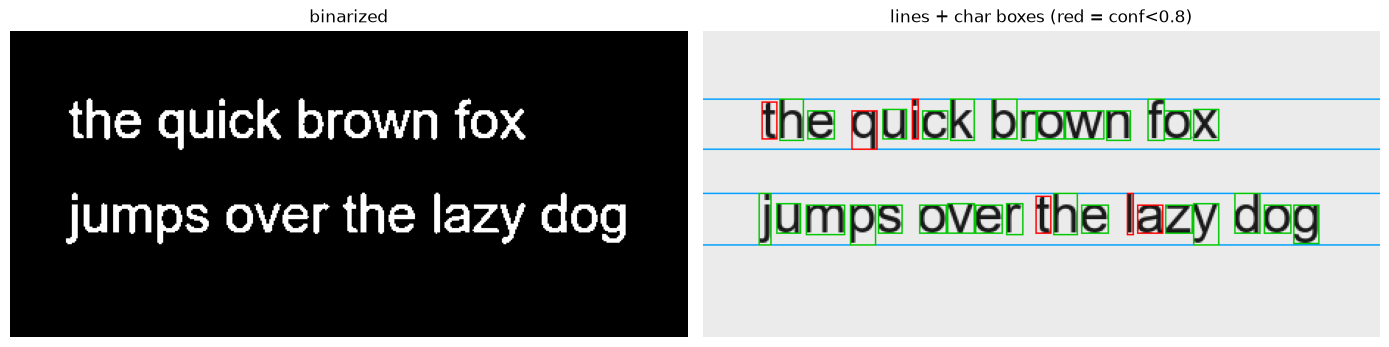

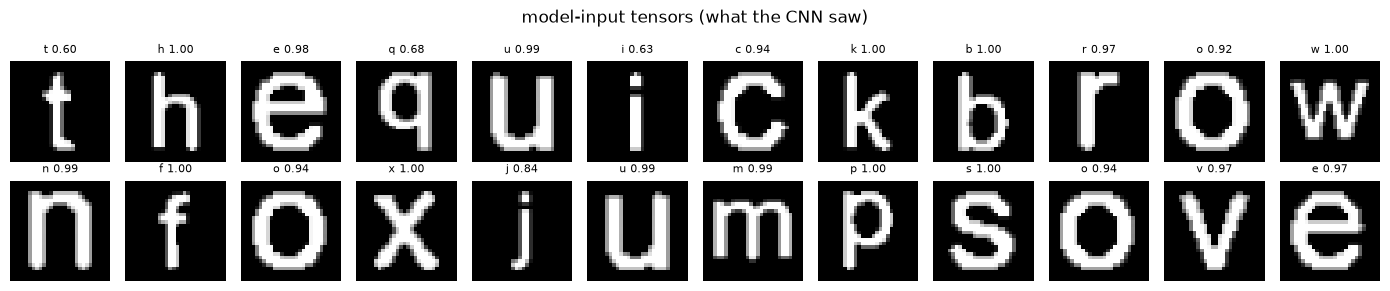

In [5]:
def show_stages(img_bgr, page, max_crops=24):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(page.binary, cmap='gray'); axes[0].set_title('binarized')
    vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
    for line in page.lines:
        y0, y1 = line.band
        cv2.line(vis, (0, y0), (vis.shape[1], y0), (0, 160, 255), 1)
        cv2.line(vis, (0, y1), (vis.shape[1], y1), (0, 160, 255), 1)
        for c in line.chars:
            b = c.box
            col = (0, 200, 0) if c.confidence > 0.8 else (255, 0, 0)
            cv2.rectangle(vis, (b.x, b.y), (b.x+b.w, b.y+b.h), col, 1)
    axes[1].imshow(vis); axes[1].set_title('lines + char boxes (red = conf<0.8)')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

    crops = [c for l in page.lines for c in l.chars][:max_crops]
    if crops:
        fig, axes = plt.subplots(2, 12, figsize=(14, 3))
        for ax, c in zip(axes.flat, crops):
            ax.imshow(c.tensor.squeeze(), cmap='gray')
            ax.set_title(f"{c.letter} {c.confidence:.2f}", fontsize=8)
        for ax in axes.flat: ax.axis('off')
        plt.suptitle('model-input tensors (what the CNN saw)')
        plt.tight_layout(); plt.show()

show_stages(synthetic, page)

## 3. Real photos + CER
Drop photos into `ml/test_images/` as `.jpg`/`.png`, each with ground truth in
`<same-name>.gt.txt` (lowercase a-z and spaces/newlines ONLY — the model knows
nothing else; digits/punctuation in the photo will hurt CER, document this).

Photo guidelines (also report material): printed text, several fonts and sizes;
a few handwritten samples; vary lighting (window light, lamp, shadow across page);
hold the phone roughly parallel to the page; 20-50 images total.

In [6]:
import jiwer

def normalize_gt(s):
    return ' '.join(s.lower().split())

rows = []
for img_path in sorted(TEST_IMAGES.glob('*.[jp][pn]g')):
    gt_path = img_path.with_suffix('').with_suffix('.gt.txt') \
              if img_path.suffix else None
    gt_file = img_path.parent / (img_path.stem + '.gt.txt')
    if not gt_file.exists():
        print(f"SKIP {img_path.name}: no ground truth ({gt_file.name})")
        continue
    img = cv2.imread(str(img_path))
    page = transcribe(img, rec)
    gt = normalize_gt(gt_file.read_text(encoding='utf-8'))
    hyp = normalize_gt(page.text)
    cer = jiwer.cer(gt, hyp) if gt else float('nan')
    rows.append({'image': img_path.name, 'cer': round(cer, 4),
                 'gt_len': len(gt), 'hyp_len': len(hyp)})
    print(f"{img_path.name:35s} CER={cer:.3f}")

if rows:
    cers = [r['cer'] for r in rows]
    summary = {'n_images': len(rows),
               'cer_mean': round(float(np.mean(cers)), 4),
               'cer_median': round(float(np.median(cers)), 4),
               'cer_best': round(min(cers), 4), 'cer_worst': round(max(cers), 4),
               'per_image': rows}
    json.dump(summary, open(ARTIFACTS / 'cer_results.json', 'w'), indent=2)
    print(f"\nmean CER={summary['cer_mean']}  median={summary['cer_median']}"
          f"  (n={len(rows)}) -> saved cer_results.json")
else:
    print('\nNo evaluated images yet — add photos + .gt.txt files and re-run.')

geom_angle.jpg                      CER=0.154
geom_bent.jpg                       CER=0.000
geom_blur.jpg                       CER=0.000
geom_close.jpg                      CER=0.128
geom_far.jpg                        CER=0.000
hand_capitals.jpg                   CER=0.121
hand_fox.jpg                        CER=0.093
hand_pipeline.jpg                   CER=0.349
hand_spaced.jpg                     CER=0.321
hand_strokes.jpg                    CER=0.182
light_dim.jpg                       CER=0.216
light_shadow_horizontal.jpg         CER=0.054
light_shadow_vertical.jpg           CER=0.216
light_sidelamp.jpg                  CER=0.108
light_warm.jpg                      CER=0.054
print_baseline_angle.jpg            CER=0.026
print_baseline_shadow.jpg           CER=0.000
print_mono_small.jpg                CER=0.281
print_mono_taxi.jpg                 CER=0.159
print_sans_fox.jpg                  CER=0.000
print_sans_spacing.jpg              CER=0.057
print_sans_sunrise.jpg            

## 4. Golden-test vectors for the Kotlin port
Freezes (input glyph -> expected 28x28 tensor -> expected prediction) triplets.
The Android `Recognizer.kt` must reproduce the tensors within atol=1/255 and the
predictions exactly. THIS is what makes "byte-for-byte identical preprocessing"
checkable instead of aspirational.

In [10]:
GOLDEN = ARTIFACTS / 'golden'
GOLDEN.mkdir(exist_ok=True)

golden_src = cv2.imread(str(TEST_IMAGES / 'print_sans_fox.jpg'))
page = transcribe(golden_src, rec)
chars = [c for l in page.lines for c in l.chars]
picks = chars[:3] + chars[len(chars)//2:len(chars)//2+2]   # 5 varied glyphs

manifest = []
for i, c in enumerate(picks):
    b = c.box
    glyph = page.binary[b.y:b.y+b.h, b.x:b.x+b.w]
    cv2.imwrite(str(GOLDEN / f'glyph_{i}.png'), glyph)          # INPUT
    np.save(GOLDEN / f'tensor_{i}.npy', c.tensor)               # EXPECTED tensor
    manifest.append({'glyph': f'glyph_{i}.png', 'tensor': f'tensor_{i}.npy',
                     'expected_letter': c.letter,
                     'expected_confidence': round(c.confidence, 4),
                     'tensor_checksum': round(float(c.tensor.sum()), 6)})
json.dump({'atol': 1/255, 'constants': {
              'ADAPTIVE_BLOCK_SIZE': pp.ADAPTIVE_BLOCK_SIZE,
              'ADAPTIVE_C': pp.ADAPTIVE_C,
              'CHAR_MARGIN_FRAC': pp.CHAR_MARGIN_FRAC,
              'SPACE_GAP_FACTOR': pp.SPACE_GAP_FACTOR},
           'cases': manifest},
          open(GOLDEN / 'manifest.json', 'w'), indent=2)
print('golden vectors:', [m['glyph'] for m in manifest])
print(json.dumps(manifest[0], indent=2))

golden vectors: ['glyph_0.png', 'glyph_1.png', 'glyph_2.png', 'glyph_3.png', 'glyph_4.png']
{
  "glyph": "glyph_0.png",
  "tensor": "tensor_0.npy",
  "expected_letter": "t",
  "expected_confidence": 0.8906,
  "tensor_checksum": 63.537254
}


In [11]:
# JSON export of golden tensors (Kotlin-friendly)
for i in range(5):
    t = np.load(GOLDEN / f'tensor_{i}.npy')
    json.dump([round(float(v), 6) for v in t.flatten()],
              open(GOLDEN / f'tensor_{i}.json', 'w'))
print('JSON tensors exported')

JSON tensors exported


In [12]:
import numpy as np, tensorflow as tf
interp = tf.lite.Interpreter(model_path=str(ARTIFACTS / 'model_int8.tflite'))
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
print("INPUT :", inp['dtype'], inp['shape'], "quant:", inp['quantization'])
print("OUTPUT:", out['dtype'], out['shape'], "quant:", out['quantization'])

INPUT : <class 'numpy.float32'> [ 1 28 28  1] quant: (0.0, 0)
OUTPUT: <class 'numpy.float32'> [ 1 26] quant: (0.0, 0)


In [5]:
import cv2, numpy as np
for i in range(5):
    g = cv2.imread(str(ARTIFACTS / 'golden' / f'glyph_{i}.png'), cv2.IMREAD_GRAYSCALE)
    uniq = np.unique(g)
    print(f'glyph_{i}: values={uniq[:8]}{"..." if len(uniq)>8 else ""} (number of unique values: {len(uniq)})')

glyph_0: values=[  0 255] (number of unique values: 2)
glyph_1: values=[  0 255] (number of unique values: 2)
glyph_2: values=[  0 255] (number of unique values: 2)
glyph_3: values=[  0 255] (number of unique values: 2)
glyph_4: values=[  0 255] (number of unique values: 2)


## Gate checklist (Phase 4 "Done when")
- [X] Synthetic smoke test: CER <= ~0.10, stages look correct
- [X] 20-50 real photos with .gt.txt collected in ml/test_images/
- [X] CER computed and saved (cer_results.json); numbers in report notes
- [X] Golden vectors + manifest.json exported (Kotlin port contract)
- [X] git commit — phase checkpoint